# Workshop 1 Fundamentos de Aprendizaje automático

- Jacobo Giraldo
- Nicolás Zapata

## Fase 1 Reconocimiento
1. Lea la documentación del dataset, y reconozca cual es su tema de trabajo.

    El problema de interés del dataset titanic es predecir si un pasajero del titanic sobrevive o no (conocido como "outcome" o resultado) entrenando un modelo predictivo usando un dataset 891 registros de pasajeros consistiendo de 12 features cada uno.

2. Cargue el dataset con pandas y muestre las primeras y últimas 5 filas (head(), tail()).

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import pandas as pd
import zipfile
import matplotlib.pyplot as plt

try:
  train = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/data/train.csv')
except:
  train = pd.read_csv('/content/Fundamentos_de_Aprendizaje_Automatico_2026-2/Workshops/train.csv')

In [3]:
train.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
train.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.00,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.00,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.45,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.00,C148,C
890,891,0,3,"Dooley, Mr. Patrick",male,32.0,0,0,370376,7.75,NaN,Q


3. Indique cuántas filas y columnas tiene el dataset (.shape) y qué representa cada una (diccionario de datos: nombre de
columna + tipo de dato esperado).

In [5]:
print(train.shape)
print(train.dtypes)

(891, 12)
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


- PassengerId: Identificación del pasajero: Numerico
- Survived: Si el pasajero sobrevivio: True -> (1), False ->(0)
- Pclass: Clase en la que viaja el pasajero: Numerico
- SibSp: Hermanos, hermanas, hermanastros o esposos/as con las que viajaba
- Parch: Numero de padres, madres, hijos o hijastros con los que viajaba


4. Use .info() y .dtypes para identificar qué columnas son numéricas, categóricas o de fecha.

In [6]:
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


- Categóricas: Survived, Pclass, Sex, Embarked.
- Numéricas: Age, Fare, SibSp, Parch
- Fecha: No hay

5. Use .describe() para las columnas numéricas. Interprete al menos 3 estadísticos (media, desviación estándar,
mínimo/máximo) en términos del problema (no solo el número).

In [7]:
train.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


- La desviación estándar de edad de 14.5 años respecto a la media de 29.6 nos refleja que una amplia distribución de los datos, con una predominancia importante de pasajeros adultos jóvenes.

- El promedio de la variable survived nos indica el porcentaje de pasajeros dentro del dataset que sobrevivieron, 38.3%.

- Los percentiles de clase representan la distribución de los individuos con alto estatus o poder económico a bordo, siendo más del 75% de segunda o tercera clase.

6. Convierta al menos una columna numérica a un array de NumPy (.values o .to_numpy()) y calcule manualmente con
funciones de NumPy (no pandas) su media, mediana y desviación estándar (np.mean, np.median, np.std).

In [8]:
import numpy as np
sibsp_arr = train['SibSp'].to_numpy()
print('Mean ', np.mean(sibsp_arr))
print('Median ', np.median(sibsp_arr))
print('Std ', np.std(sibsp_arr))

Mean  0.5230078563411896
Median  0.0
Std  1.1021244350892878


## Fase 2 Limpieza
7. Identifique valores nulos por columna (.isnull().sum()) y calcule qué porcentaje representan del total de filas.

In [9]:
for column in train.columns:
  null_values = train[column].isnull().sum()
  print(f'{column}: null_pct = {null_values/train[column].shape[0]*100}')

PassengerId: null_pct = 0.0
Survived: null_pct = 0.0
Pclass: null_pct = 0.0
Name: null_pct = 0.0
Sex: null_pct = 0.0
Age: null_pct = 19.865319865319865
SibSp: null_pct = 0.0
Parch: null_pct = 0.0
Ticket: null_pct = 0.0
Fare: null_pct = 0.0
Cabin: null_pct = 77.10437710437711
Embarked: null_pct = 0.22446689113355783


8. Proponga y justifique una estrategia de tratamiento para los nulos encontrados (eliminar filas, imputar con
media/mediana/moda, imputar con un valor constante, etc.). Aplíquela.

In [10]:
# Eliminación de columnas
#  Cabin: No hay data suficiente para imputar valores faltantes
#  Embarked: Lugar de embarcación es irrelevante para problema de supervivencia
train.drop(columns=['Cabin'], inplace = True)

# Imputamos faltantes en columna Age utilizando promedio por sexo
gender_age_mean = train.groupby('Sex')['Age'].mean()
train.fillna({'Age': train['Sex'].map(gender_age_mean)}, inplace=True)
# Imputamos faltantes en columna Embarked utilizando la moda
train.fillna({'Embarked': train['Embarked'].mode()[0]}, inplace=True)
train.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          891 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Embarked     891 non-null    object 
dtypes: float64(2), int64(5), object(4)
memory usage: 76.7+ KB


9. Identifique y elimine filas duplicadas si existen (.duplicated(), .drop_duplicates()). Reporte cuántas se eliminaron.

In [11]:
train.duplicated().sum()
# No hay filas duplicadas, por lo que no se debe eliminar ninguna

np.int64(0)

10. Revise si hay inconsistencias de formato en columnas categóricas o de texto (ej. "Yes"/"yes"/"YES", espacios extra,
mayúsculas/minúsculas) usando .unique() y corríjalas.

In [12]:
for column in train[['Survived', 'Sex', 'Pclass']].columns:
  print(f'{column}: {train[column].unique()}')
# No hay inconsistencias de formato en columnas categóricas

Survived: [0 1]
Sex: ['male' 'female']
Pclass: [3 1 2]


11. Identifique posibles valores atípicos (outliers) en al menos una columna numérica usando el criterio de rango
intercuartílico (IQR). No es obligatorio eliminarlos, pero sí reportarlos. Para este punto hago el reporte manual
basándose en las operaciones vistas en clase

In [13]:
Q1 = train['Fare'].quantile(0.25)
Q3 = train['Fare'].quantile(0.75)

IRQ = Q3 - Q1

print(f"Q1: {Q1}, Q3: {Q3}, IRQ: {IRQ}")

upper_bound = Q3 + 1.5 * IRQ
lower_bound = Q1 - 1.5 * IRQ

print(f"Upper Bound: {upper_bound}, Lower Bound: {lower_bound}")

# Imposible Fare < 0, así que lower_bound = 0
lower_bound = 0

outliers = train[(train['Fare'] > upper_bound) | (train['Fare'] < lower_bound)]
print(f"Outliers: {outliers.shape[0]}")

Q1: 7.9104, Q3: 31.0, IRQ: 23.0896
Upper Bound: 65.6344, Lower Bound: -26.724
Outliers: 116


## Fase 3 EDA
12. Usando .unique() y/o .value_counts(), identifique las categorías presentes en al menos dos columnas categóricas y
cuántos registros tiene cada una.

In [14]:
survived_map = {0: 'No', 1: 'Yes'}
train['Survived'].map(survived_map).value_counts()

,count
Survived,
No,549
Yes,342


13. Construya un diccionario donde la clave sea una categoría relevante del dataset y el valor sea una métrica agregada
(promedio, conteo, máximo, etc.) calculada solo para un subconjunto filtrado de los datos (similar al ejercicio de
tipo de dolor de pecho visto en clase).

In [15]:
# Promedio de la edad de los sobrevivientes por sexo
survivors_age_average_by_gender = {}
survivors = train.loc[train['Survived'] == 1]
for sex in survivors['Sex'].unique():
  survivors_age_average_by_gender[sex] = survivors[survivors['Sex'] == sex]['Age'].mean()
print(survivors_age_average_by_gender)


{'female': np.float64(28.70371466627201), 'male': np.float64(27.782534985924624)}


14. Use .groupby() para responder al menos dos preguntas de negocio/análisis específicas del dataset asignado (ej.
"¿Cuál es el promedio de X según la categoría Y?").

In [16]:
train.groupby('Sex')['Age'].mean()

,Age
Sex,
female,27.915709
male,30.726645


In [17]:
train.groupby('Pclass')['Age'].mean()

,Age
Pclass,
1,37.073708
2,29.897833
3,26.447422


15. Ordene el dataset (.sort_values()) para identificar los 5 registros más altos y los 5 más bajos según una variable
numérica relevante. Interprete brevemente qué representan esos extremos.


In [18]:
parch_sort = train.sort_values('Parch', ascending=False)
parch_sort.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
678,679,0,3,"Goodwin, Mrs. Frederick (Augusta Tyler)",female,43.0,1,6,CA 2144,46.9000,S
610,611,0,3,"Andersson, Mrs. Anders Johan (Alfrida Konstant...",female,39.0,1,5,347082,31.2750,S
638,639,0,3,"Panula, Mrs. Juha (Maria Emilia Ojala)",female,41.0,0,5,3101295,39.6875,S
13,14,0,3,"Andersson, Mr. Anders Johan",male,39.0,1,5,347082,31.2750,S
885,886,0,3,"Rice, Mrs. William (Margaret Norton)",female,39.0,0,5,382652,29.1250,Q


In [19]:
parch_sort.tail()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
20,21,0,2,"Fynney, Mr. Joseph J",male,35.0,0,0,239865,26.0000,S
21,22,1,2,"Beesley, Mr. Lawrence",male,34.0,0,0,248698,13.0000,S
22,23,1,3,"McGowan, Miss. Anna ""Annie""",female,15.0,0,0,330923,8.0292,Q
23,24,1,1,"Sloper, Mr. William Thompson",male,28.0,0,0,113788,35.5000,S
6,7,0,1,"McCarthy, Mr. Timothy J",male,54.0,0,0,17463,51.8625,S


Representan los valores límite para el número de padres o hijos de un determinado pasajero, o sea el rango de esta variable.

#Fase 4 Visualización
Para cada gráfica, incluya el código, la imagen generada, y un párrafo de interpretación (qué observa, qué le sugiere sobre los
datos), y cuál sería su recomendación como persona encargada de la toma de decisiones:


16. Gráfico de barras: distribución de una variable categórica relevante.

        Survived
Sex             
female       233
male         109


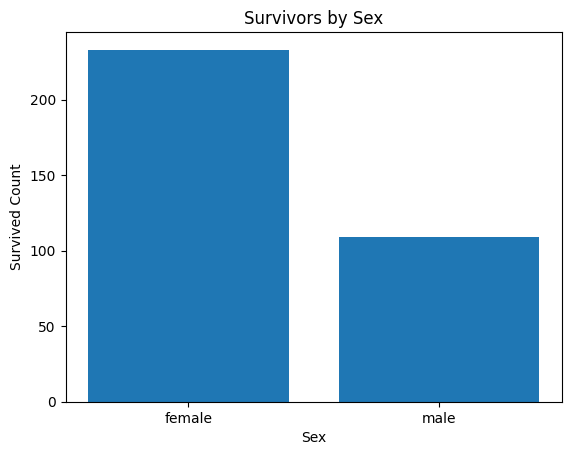

In [20]:
table = pd.pivot_table(data=train, index='Sex', values='Survived', aggfunc='sum')
print(table)
plt.bar(table.index, table['Survived'])
plt.xlabel('Sex')
plt.ylabel('Survived Count')
plt.title('Survivors by Sex')
plt.show()

In [21]:
train['Sex'].value_counts()

,count
Sex,
male,577
female,314


In [22]:
train['Sex'].value_counts()
porcentaje_hombres = 109/577
porcentaje_mujeres = 233/314
print(f"Porcentaje de hombres: {porcentaje_hombres*100}")
print(f"Porcentaje de mujeres: {porcentaje_mujeres*100}")

Porcentaje de hombres: 18.890814558058924
Porcentaje de mujeres: 74.20382165605095


Es un dato relevante que nos dice cuales eran las probabilidades de sobrevivir siendo un hombre o mujer, en donde predomina la supervivencia de los mujeres sobre los hombres.
Del total de hombres sobrevivó el 18.89% y del total de mujeres sobrevivió el 74.2%.
Mi decisión como encargado sería categorizar esos hombres por niños y priorizar las mujeres y niños.

17. Gráfico de pie: proporción de una variable categórica binaria o con pocas categorías.

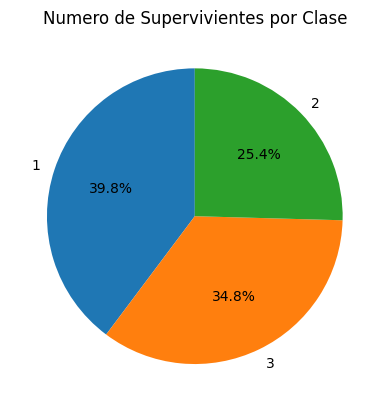

In [29]:
pclass_counts = survivors['Pclass'].value_counts()

percentages = pclass_counts / pclass_counts.sum() * 100

plt.pie(percentages, labels=pclass_counts.index, autopct='%1.1f%%', startangle=90)
plt.title('Numero de Supervivientes por Clase')
plt.show()

Nos inidca la cantidad porcentual de pasajeros que sobrevivieron por clase, lo cual nos dice que el 39.8% eran pasajeros de primera clase, aunque la distribución es relativamente uniforme dando 34.8% de los sobrevivientes eran de tercera clase pese a ser "menos privilegiados". El valor menor de 25.4% para la segunda clase podría ser un efecto de variables no contempladas en el dataset, como la ubicación de las cabinas de segunda clase.

18. Histograma: distribución de una variable numérica. Indique si es simétrica o sesgada.

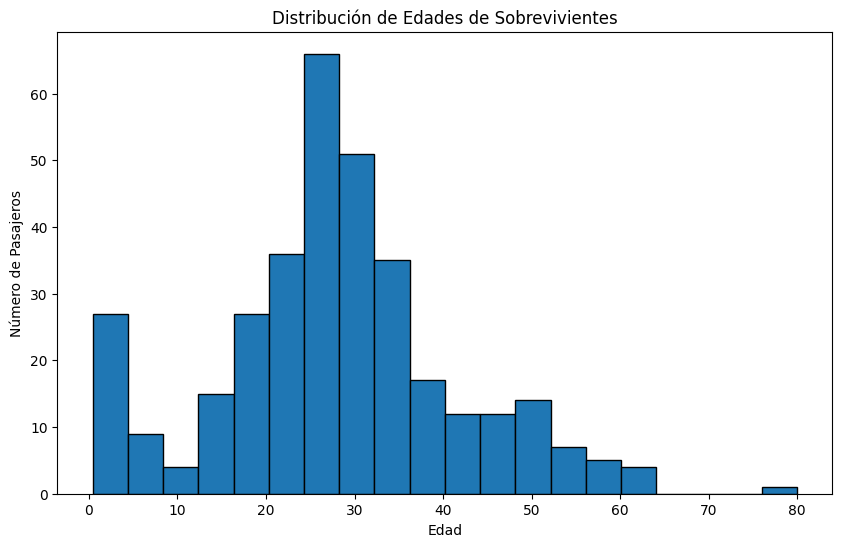

In [31]:
fig, ax = plt.subplots(figsize=(10, 6))
ax.hist(survivors['Age'], bins=20, edgecolor='black')

ax.set_title("Distribución de Edades de Sobrevivientes")
ax.set_xlabel("Edad")
ax.set_ylabel("Número de Pasajeros")

plt.show()

Es sesgada a la derecha y podemos ver la distribución del número de pasajeros por edades

19. Scatter plot: relación entre dos variables numéricas. Indique si observa correlación (positiva, negativa o nula).


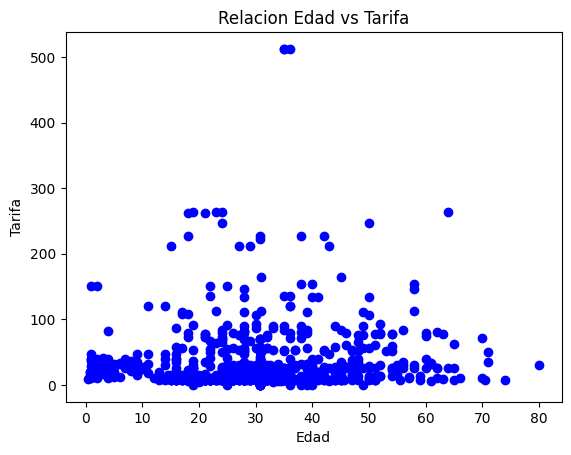

In [25]:
plt.scatter(train['Age'], train['Fare'], color ='blue')
plt.xlabel('Edad')
plt.ylabel('Tarifa')
plt.title('Relacion Edad vs Tarifa')
plt.show()

Permite observar que no existe una relación lineal evidente entre la edad de los pasajeros y la tarifa pagada

20. Boxplot: para al menos una variable numérica, generado con .boxplot() o seaborn. Identifique visualmente si hay
outliers y relaciónelo con lo encontrado en el numeral 10.


/tmp/ipykernel_2546/392666035.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([male_sibsp, female_sibsp], labels=['male', 'female'])


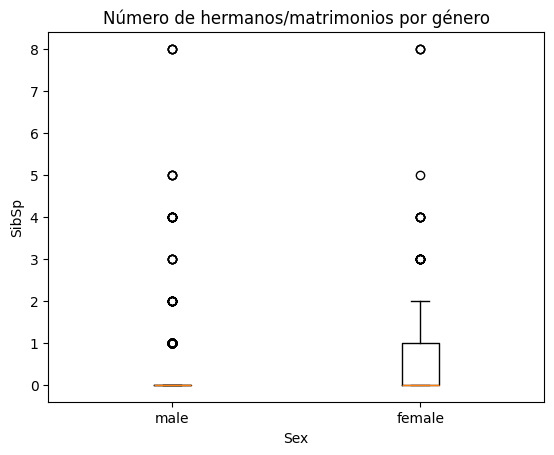

In [26]:
male_sibsp = train[train['Sex'] == 'male']['SibSp'].dropna()
female_sibsp = train[train['Sex'] == 'female']['SibSp'].dropna()

plt.boxplot([male_sibsp, female_sibsp], labels=['male', 'female'])
plt.xlabel('Sex')
plt.ylabel('SibSp')
plt.title('Número de hermanos/matrimonios por género')
plt.show()

se observa valores atípicos en la variable SibSp, en los pasajeros que tenían un número elevado de hermanos o matrimonios.
pero estos valores no corresponden a inconsistencias de formato por lo que se verifica con el punto 10

21. Gráfico de líneas (plot convencional): solo si el dataset tiene una variable temporal (fecha, año, mes). Si no
aplica, reemplace por un segundo boxplot comparando la variable numérica principal entre 2 o más categorías (ej.
boxplot de precio por género).

/tmp/ipykernel_2546/985511572.py:4: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot([male_fare, female_fare], labels=['male', 'female'])


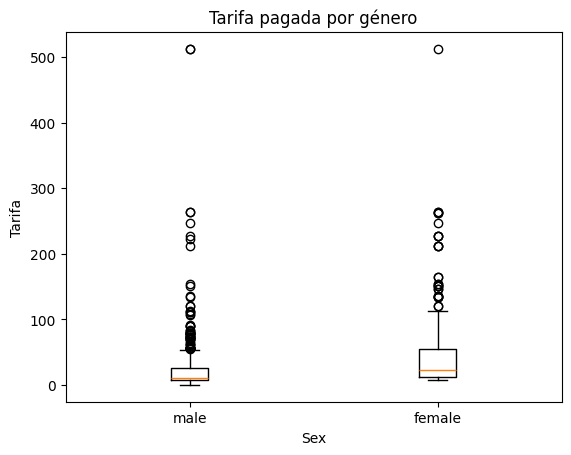

In [27]:
male_fare = train[train['Sex'] == 'male']['Fare'].dropna()
female_fare = train[train['Sex'] == 'female']['Fare'].dropna()

plt.boxplot([male_fare, female_fare], labels=['male', 'female'])
plt.xlabel('Sex')
plt.ylabel('Tarifa')
plt.title('Tarifa pagada por género')
plt.show()

las mujeres presentan una mayor dispersión en las tarifas y también algunos valores atípicos de tarifas elevadas.

## Fase 5 Conclusiones
22. Redacte un párrafo de conclusiones generales: ¿qué aprendió del dataset?, ¿qué variables parecen más relevantes?,
¿qué limpieza fue necesaria y por qué?, ¿qué preguntas quedarían abiertas para un futuro modelo de Machine
Learning sobre estos datos?, use un subplot (2,2) con los gráficos que considere mas importantes para explicar sus
hallazgos generales.

Observamos la tendencia de supervivencia con distintas variables y aprendimos a aplicar Análisis exploratorio de datos en el contexto del accidente del titanic. En el dataset se evidencia una tendencia clara a la supervivencia principalmente de mujeres representando el 68.1% de los sobrevivientes, siendo las variables más influyentes en el resultado el sexo y la edad.

Para la limpieza realizamos la eliminación de la columna correspondiente al número de cabina debido a que faltaba el 77% de los registros, también se imputaron los datos de edad faltantes usando el promedio por sexo, y los datos de embarcación usando la moda dado que el dato era categórico y menos de 1% de la información faltaba.

Preguntas pertinentes para entrenamiento de un modelo predictivo:
- ¿Las columnas de id, nombre, ticket, tarifa, cabina y puerto de embarcación son realmente relevantes para la predicción?
- Cuál es la correlación entre la clase del pasajero y su resultado de supervivencia? Permitiría obviar la clase como entrada para el modelo?
- Matriz de correlación de variables numéricas
- Normalización de variables numéricas

/tmp/ipykernel_2546/1249169551.py:29: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1,1].boxplot([male_fare, female_fare], labels=['male', 'female'])


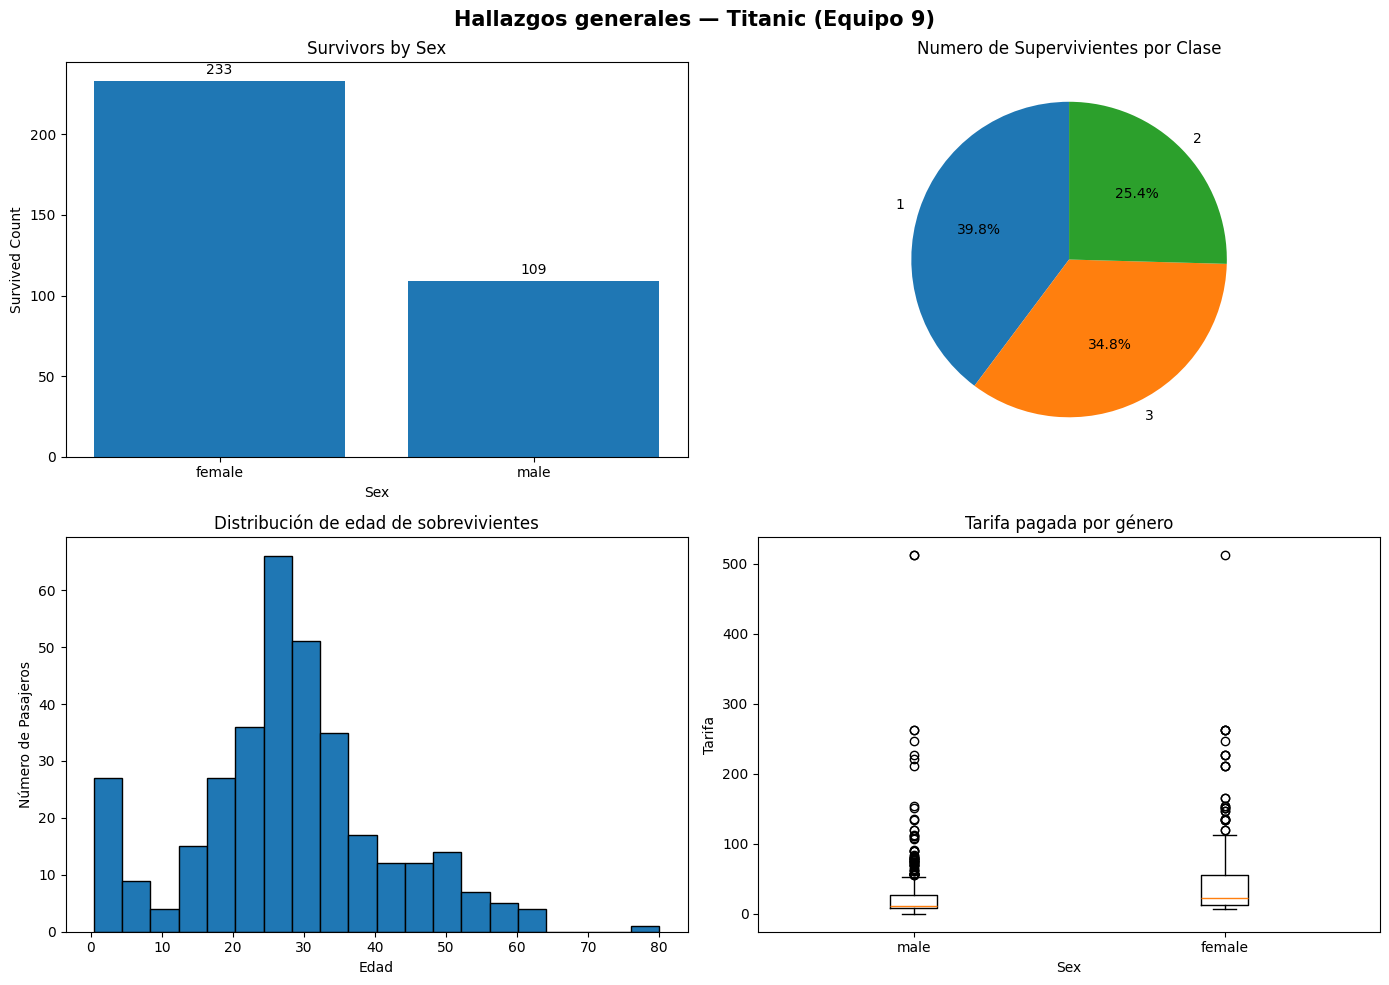

In [38]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle('Hallazgos generales — Titanic (Equipo 9)', fontsize=15, fontweight='bold')

# (0,0) Tasa de supervivencia por sexo
table = pd.pivot_table(data=train, index='Sex', values='Survived', aggfunc='sum')
b = axes[0, 0].bar(table.index, table['Survived'])
axes[0,0].set_xlabel('Sex')
axes[0,0].set_ylabel('Survived Count')
axes[0,0].set_title('Survivors by Sex')
axes[0, 0].bar_label(b, fmt='%.0f', padding=3)

# (0,1) Número de supervivientes por clase
pclass_counts = survivors['Pclass'].value_counts()
percentages = pclass_counts / pclass_counts.sum() * 100
b = axes[0,1].pie(percentages, labels=pclass_counts.index, autopct='%1.1f%%', startangle=90)
axes[0,1].set_title('Numero de Supervivientes por Clase')


# (1,0) Distribución de edad: sobrevivientes
axes[1,0].hist(survivors['Age'], bins=20, edgecolor='black')
axes[1,0].set_title("Distribución de Edades de Sobrevivientes")
axes[1,0].set_xlabel("Edad")
axes[1,0].set_ylabel("Número de Pasajeros")
axes[1,0].set_title('Distribución de edad de sobrevivientes')

# (1,1) Tarifa por resultado
male_fare = train[train['Sex'] == 'male']['Fare'].dropna()
female_fare = train[train['Sex'] == 'female']['Fare'].dropna()
axes[1,1].boxplot([male_fare, female_fare], labels=['male', 'female'])
axes[1,1].set_xlabel('Sex')
axes[1,1].set_ylabel('Tarifa')
axes[1,1].set_title('Tarifa pagada por género')

plt.tight_layout()
plt.show()